# House prices in Ames, Iowa

Regression on the Kaggle [Housing Prices Competition for Kaggle Learn Users](https://www.kaggle.com/competitions/home-data-for-ml-course): predict `SalePrice` for 1,459 houses from 79 descriptive columns, learning from 1,460 sold houses. The metric is the RMSE of the logarithm of the price, so an error of 0.10 means a typical miss of about 10%.

All the code lives in `src/housing.py`; the notebook calls it and shows the reasoning.

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, cross_val_predict

sys.path.insert(0, str(Path("src").resolve()))
import housing as h

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print("train:", train.shape, " test:", test.shape)
train[["Id", "MSSubClass", "Neighborhood", "OverallQual", "GrLivArea", "YearBuilt", "SalePrice"]].head()

train: (1460, 81)  test: (1459, 80)


,Id,MSSubClass,Neighborhood,OverallQual,GrLivArea,YearBuilt,SalePrice
0,1,60,CollgCr,7,1710,2003,208500
1,2,20,Veenker,6,1262,1976,181500
2,3,60,CollgCr,7,1786,2001,223500
3,4,70,Crawfor,7,1717,1915,140000
4,5,60,NoRidge,8,2198,2000,250000


## 1. The target

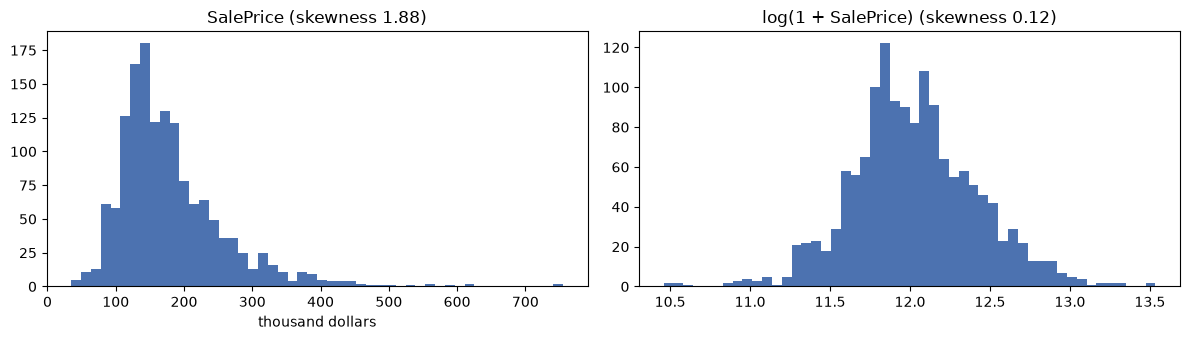

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(train["SalePrice"] / 1000, bins=50, color="#4c72b0")
axes[0].set_title(f"SalePrice (skewness {train['SalePrice'].skew():.2f})")
axes[0].set_xlabel("thousand dollars")
axes[1].hist(np.log1p(train["SalePrice"]), bins=50, color="#4c72b0")
axes[1].set_title(f"log(1 + SalePrice) (skewness {np.log1p(train['SalePrice']).skew():.2f})")
plt.tight_layout()

Prices are skewed to the right. The models learn `log(1 + price)`, which is almost symmetric and matches the competition metric; predictions are converted back with `exp(x) - 1`.

## 2. What drives the price

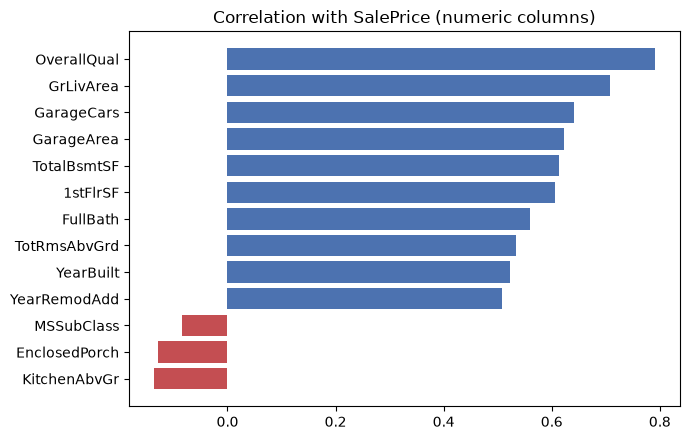

In [3]:
numeric = train.select_dtypes("number").drop(columns=["Id"])
corr = numeric.corr()["SalePrice"].drop("SalePrice").sort_values()
top = pd.concat([corr.head(3), corr.tail(10)])
plt.figure(figsize=(7, 4.5))
plt.barh(top.index, top.values, color=["#c44e52" if v < 0 else "#4c72b0" for v in top.values])
plt.title("Correlation with SalePrice (numeric columns)")
plt.tight_layout()

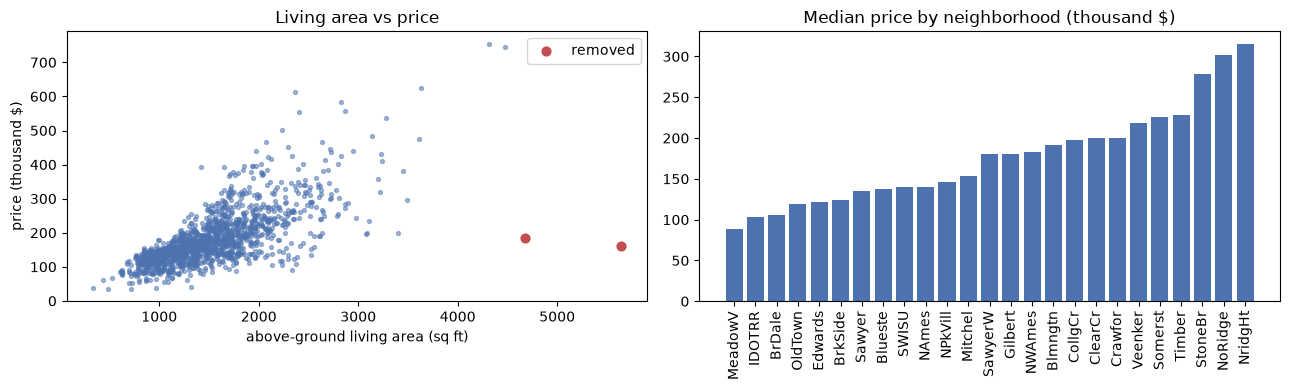

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
outlier = (train["GrLivArea"] > 4000) & (train["SalePrice"] < 300_000)
axes[0].scatter(train.loc[~outlier, "GrLivArea"], train.loc[~outlier, "SalePrice"] / 1000, s=8, alpha=0.5, color="#4c72b0")
axes[0].scatter(train.loc[outlier, "GrLivArea"], train.loc[outlier, "SalePrice"] / 1000, s=40, color="#c44e52", label="removed")
axes[0].set_xlabel("above-ground living area (sq ft)")
axes[0].set_ylabel("price (thousand $)")
axes[0].legend()
axes[0].set_title("Living area vs price")

by_hood = train.groupby("Neighborhood")["SalePrice"].median().sort_values() / 1000
axes[1].bar(by_hood.index, by_hood.values, color="#4c72b0")
axes[1].set_title("Median price by neighborhood (thousand $)")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()

Overall quality and size explain most of the price. Two houses (in red) have over 4,000 sq ft of living area and sold for under $200,000; they were partial sales of unfinished houses, and the dataset's author recommends removing them. They are dropped from training. Location matters too: the median price differs by a factor of more than three between neighborhoods.

## 3. Missing values usually mean "none"

In [5]:
missing = train.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "share": (missing / len(train)).round(3)}).head(12)

,missing,share
PoolQC,1453,0.995
MiscFeature,1406,0.963
Alley,1369,0.938
Fence,1179,0.808
MasVnrType,872,0.597
FireplaceQu,690,0.473
LotFrontage,259,0.177
GarageType,81,0.055
GarageYrBlt,81,0.055
GarageFinish,81,0.055


According to `data/data_description.txt`, a missing `PoolQC`, `Alley`, `Fence`, `FireplaceQu`, garage or basement value means the house has no pool, alley, fence, fireplace, garage or basement. `add_features` fills those with `"None"` (or 0 for areas and counts) instead of guessing the most frequent value. Only a handful of genuinely unknown values remain, and the pipeline imputes them.

## 4. Features

In [6]:
clean = h.remove_outliers(train)
X, y_log = h.add_features(clean), np.log1p(clean["SalePrice"])
print(f"{X.shape[1]} columns after cleaning and feature engineering, {len(X)} houses")
X[["TotalSF", "TotalBath", "TotalPorchSF", "HouseAge", "YearsSinceRemodel", "HasGarage", "MSSubClass"]].head()

86 columns after cleaning and feature engineering, 1458 houses


,TotalSF,TotalBath,TotalPorchSF,HouseAge,YearsSinceRemodel,HasGarage,MSSubClass
0,2566,3.5,61,5,5,1,60
1,2524,2.5,298,31,31,1,20
2,2706,3.5,42,7,6,1,60
3,2473,2.0,307,91,36,1,70
4,3343,3.5,276,8,8,1,60


Changes with respect to the raw data:

- **Dropped**: `Id` (a row number, not a property of the house) and `Utilities` (one house differs from the rest).
- **Codes as categories**: `MSSubClass` (dwelling type), `MoSold` and `YrSold` are numbers that work as labels.
- **Ordered scales as numbers**: quality and condition columns (`Po` < `Fa` < `TA` < `Gd` < `Ex`) and basement and garage finish levels keep their order.
- **New**: total square footage, total bathrooms, total porch area, age at sale, years since remodelling, and flags for garage, basement and second floor.
- **For the linear model only**: numeric columns on a log scale and standardised. The tree models use them as they are.

## 5. Model comparison

In [7]:
results = h.compare_models(train, n_repeats=3)
results.round(4)

,model,rmse_log,std
0,Ridge + boosting (average),0.1128,0.0066
1,Ridge (linear),0.1160,0.0067
2,Gradient boosting,0.1235,0.0066
3,Random forest,0.1296,0.0049
4,"Previous version (random forest, raw columns)",0.1384,0.0068


RMSE of log price, mean over 5-fold cross-validation repeated 3 times (15 fits per model), on the same 1,458 houses and the same folds for every model. "Previous version" is the model this repository used before: a random forest on the raw columns, with `Id` as a feature and no cleaning.

The regularised linear model (ridge) beats both tree models once the features are prepared: prices grow smoothly with size and quality, which suits a linear model on log scales. Averaging ridge with gradient boosting is better than either alone, because their errors are only partly correlated. Together the changes cut the error by about 18% with respect to the previous version.

## 6. Where the model misses

Ridge + boosting (average): median absolute error 5.6%, within 10%: 76% of houses, within 20%: 94%


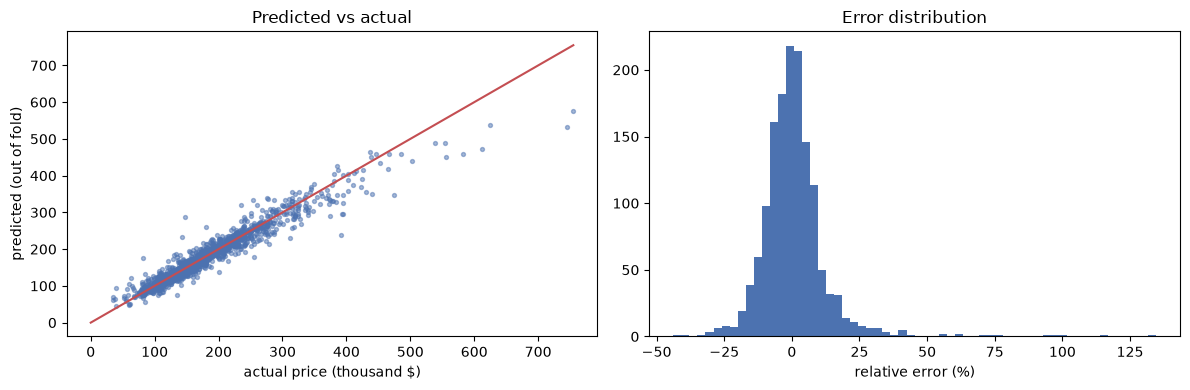

In [8]:
best_name = results.loc[results["model"].isin(h.candidate_models()), "model"].iloc[0]
pred_log = cross_val_predict(h.candidate_models()[best_name], X, y_log,
                             cv=KFold(5, shuffle=True, random_state=h.RANDOM_STATE), n_jobs=-1)
errors = np.expm1(pred_log) / np.expm1(y_log) - 1
print(f"{best_name}: median absolute error {np.median(np.abs(errors)):.1%}, "
      f"within 10%: {(np.abs(errors) < 0.10).mean():.0%} of houses, within 20%: {(np.abs(errors) < 0.20).mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(np.expm1(y_log) / 1000, np.expm1(pred_log) / 1000, s=8, alpha=0.5, color="#4c72b0")
lim = [0, np.expm1(y_log).max() / 1000]
axes[0].plot(lim, lim, color="#c44e52")
axes[0].set_xlabel("actual price (thousand $)")
axes[0].set_ylabel("predicted (out of fold)")
axes[0].set_title("Predicted vs actual")
axes[1].hist(errors * 100, bins=60, color="#4c72b0")
axes[1].set_xlabel("relative error (%)")
axes[1].set_title("Error distribution")
plt.tight_layout()

Each house is predicted by a model that did not see it during training. The median miss is 5.6%, and three houses out of four are predicted within 10% of their real price. About 6% miss by more than 20%; those are the cases the 79 columns do not explain well.

## 7. Submission

In [9]:
model, submission = h.fit_and_predict(train, test, best_name)
submission.to_csv("submission.csv", index=False)
print(f"{best_name} fitted on {len(clean)} houses; {len(submission)} predictions written to submission.csv")
submission.describe().loc[["mean", "min", "50%", "max"], ["SalePrice"]].round(0)

Ridge + boosting (average) fitted on 1458 houses; 1459 predictions written to submission.csv


,SalePrice
mean,178318.0
min,46667.0
50%,157120.0
max,680789.0
